<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/60_integracion/61_correlaciones_espaciales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 61 · Correlaciones espaciales entre fuego, lluvia, suelo y expansión (celdas de 2 km)

**Autoras:** Katalina y Michelle

**Pregunta:** en la misma unidad espacial (celdas de 2 km), ¿cómo se relacionan el fuego, la lluvia de la temporada seca, la acidez del suelo y la expansión agropecuaria? En particular, la hipótesis planteada por el profesor: **¿las zonas más ácidas, como Cumaribo, tienen menos focos de calor?**

**Entradas** (`datos/comunes/`, todas con la llave `id_celda`):

| Archivo | Cuaderno | Variables que se usan |
|---|---|---|
| `grilla_2km.gpkg` | 02 (Daniel) | geometría, municipio, `area_km2`, `frac_celda` |
| `focos_celda.csv` | 22 (Michelle) | `focos_km2_anio`, `focos_temporada_seca_media` |
| `lluvia_celda.csv` | 12 (Michelle) | `lluvia_anual_1991_2020`, `lluvia_seca_1991_2020` |
| `suelo_celda.csv` | 42 (Katalina) | `ph_medio`, `cos_medio_gkg`, `pct_area_ph_menor_5`, `clase_ph` |
| `quema_celda.csv` | 24 (Jonatan) | `quema_media_anual_pct` (**si ya está en el repo**) |
| `agro_celda.csv` | 30 (Daniel) | `agro_pct_2024`, `cambio_agro_pp` (**si ya está en el repo**) |

El cuaderno corre con las capas que existan: si `quema_celda.csv` o `agro_celda.csv` todavía no están, las omite y lo avisa. Cuando lleguen, basta con volver a ejecutarlo.

**Salidas:** `modulos/integracion/resultados/61_*.csv` y `modulos/integracion/graficas/61_*.png`.

**Métodos:** correlación de Spearman con significancia corregida por autocorrelación espacial (tamaño de muestra efectivo de Clifford, Richardson y Hémon, 1989), comparación por clase de pH, Moran global y LISA bivariado (Anselin, 1995) con 999 permutaciones.

## Paso 1. Preparar el entorno

In [1]:
# Rutas del proyecto: funcionan en Colab y en local (ver 00_configuracion)
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Los datos crudos pesados (MGN, CSV de FIRMS, copia del ONI) siguen en Drive
    CRUDOS = '/content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos'
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        !git clone -q {REPO} {RAIZ}
    # Mientras el PR #3 no esté unido a main, los datos comunes están en esta rama
    if not os.path.exists(f'{RAIZ}/datos/comunes/oni_mensual.csv'):
        !git -C {RAIZ} fetch -q origin feature/clima-fuego-datos
        !git -C {RAIZ} checkout -q feature/clima-fuego-datos
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/
    CRUDOS = os.path.join(RAIZ, 'datos', 'crudos')

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'graficas')
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    """Baja de DVC un archivo pesado del repo (por ejemplo un .gpkg) si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

print('Raíz del repo:', RAIZ)
print('Crudos:', CRUDOS, '| existe:', os.path.exists(CRUDOS))

RES_INT = os.path.join(RAIZ, 'modulos', 'integracion', 'resultados')
GRAF_INT = os.path.join(RAIZ, 'modulos', 'integracion', 'graficas')
os.makedirs(RES_INT, exist_ok=True)
os.makedirs(GRAF_INT, exist_ok=True)

try:
    import esda, libpysal
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'esda', 'libpysal'], check=True)
    import esda, libpysal

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial import cKDTree
SEMILLA = 2026
print('esda', esda.__version__, '| libpysal', libpysal.__version__)

Raíz del repo: C:\Proyectos2026-2\Proyecto-ALTILLANURA
Crudos: C:\Proyectos2026-2\Proyecto-ALTILLANURA\datos\crudos | existe: False


esda 2.10.0 | libpysal 4.15.1


## Paso 2. Unir las capas por `id_celda`

Todas las capas se unen a la grilla con `validate='one_to_one'`, que falla si algún `id_celda` está repetido.

**Qué celdas se analizan:** solo las que tienen al menos la mitad de su área dentro de la región (`frac_celda` ≥ 0,5). En las celdas de borde muy pequeñas un solo foco produce densidades extremas (por ejemplo, 1 foco en 0,14 km²), y esos valores distorsionarían las correlaciones.

In [2]:
for f in ['grilla_2km.gpkg', 'focos_celda.csv', 'lluvia_celda.csv', 'suelo_celda.csv']:
    traer(f'datos/comunes/{f}')
for f in ['quema_celda.csv', 'agro_celda.csv']:     # capas opcionales
    try:
        traer(f'datos/comunes/{f}')
    except Exception:
        pass

grilla = gpd.read_file(f'{COMUNES}/grilla_2km.gpkg')
leer = lambda f: pd.read_csv(f'{COMUNES}/{f}', dtype={'id_celda': str, 'mpio_cdpmp': str})
d = grilla.merge(leer('focos_celda.csv'), on='id_celda', how='left', validate='one_to_one')
d = d.merge(leer('lluvia_celda.csv'), on='id_celda', how='left', validate='one_to_one')
suelo = leer('suelo_celda.csv').drop(columns=['mpio_cdpmp', 'area_km2'], errors='ignore')
d = d.merge(suelo, on='id_celda', how='left', validate='one_to_one')

VARIABLES = {
    'focos_km2_anio': 'Focos por km² al año (FIRMS)',
    'lluvia_seca_1991_2020': 'Lluvia de dic–mar (mm)',
    'lluvia_anual_1991_2020': 'Lluvia anual (mm)',
    'ph_medio': 'pH del suelo',
    'cos_medio_gkg': 'Carbono orgánico (g/kg)',
}
for archivo, cols in [('quema_celda.csv', {'quema_media_anual_pct': 'Área quemada al año (%, MapBiomas)'}),
                      ('agro_celda.csv', {'agro_pct_2024': '% agropecuario 2024',
                                          'cambio_agro_pp': 'Cambio agropecuario 2000–2024 (pp)'})]:
    if os.path.exists(f'{COMUNES}/{archivo}'):
        capa = leer(archivo).drop(columns=['mpio_cdpmp', 'n_pixeles', 'area_km2'], errors='ignore')
        d = d.merge(capa, on='id_celda', how='left', validate='one_to_one')
        VARIABLES.update({k: v for k, v in cols.items() if k in d.columns})
        print('Capa incluida:', archivo)
    else:
        print('Capa NO disponible todavía (se omite):', archivo)

d['x_km'] = d['id_celda'].str.extract(r'x(\d+)_')[0].astype(int)
d['y_km'] = d['id_celda'].str.extract(r'_y(\d+)')[0].astype(int)
d = d[d['frac_celda'] >= 0.5].reset_index(drop=True)
faltan = d[list(VARIABLES)].isna().sum()
print(f'\nCeldas analizadas (frac_celda ≥ 0,5): {len(d):,} de {len(grilla):,}')
print('Valores faltantes por variable:'); print(faltan.to_string())
d = d.dropna(subset=list(VARIABLES)).reset_index(drop=True)
print(f'Celdas con todas las variables: {len(d):,}')

Capa NO disponible todavía (se omite): quema_celda.csv
Capa NO disponible todavía (se omite): agro_celda.csv



Celdas analizadas (frac_celda ≥ 0,5): 33,913 de 34,763
Valores faltantes por variable:
focos_km2_anio            0
lluvia_seca_1991_2020     0
lluvia_anual_1991_2020    0
ph_medio                  0
cos_medio_gkg             0
Celdas con todas las variables: 33,913


## Paso 3. Correlaciones de Spearman con significancia corregida

**Por qué hay que corregir.** Una correlación entre ~33.000 celdas casi siempre sale "significativa" con la prueba usual, porque esa prueba supone que cada celda es una observación independiente. Pero celdas vecinas se parecen (la lluvia de CHIRPS, por ejemplo, viene de píxeles de ~5 km): la **información real** equivale a muchas menos observaciones.

**Cómo se corrige (Clifford, Richardson y Hémon, 1989).** Se estima un **tamaño de muestra efectivo** $n_{ef}$:

1. Se pasan las dos variables a rangos (Spearman) y se estandarizan: $z_x$, $z_y$.
2. Con una muestra aleatoria de 4.000 celdas se calcula, para clases de distancia de 10 km, la autocorrelación de cada variable: $\hat\rho_x(k)$ = promedio de $z_{x,i}\,z_{x,j}$ entre los pares de celdas en la clase $k$ (lo mismo para $y$).
3. La varianza de la correlación bajo la hipótesis de no relación es aproximadamente

$$\operatorname{Var}(r) \approx \frac{1}{n} + \frac{n-1}{n}\sum_k p_k\,\hat\rho_x(k)\,\hat\rho_y(k)$$

donde $p_k$ es la proporción de pares de celdas en la clase $k$. Si las variables no tienen autocorrelación, $\operatorname{Var}(r) = 1/n$, como en la prueba usual.

4. $n_{ef} = 1/\operatorname{Var}(r)$ y la prueba usa $t = r\sqrt{(n_{ef}-2)/(1-r^2)}$ con $n_{ef} - 2$ grados de libertad.

Así, una correlación con miles de celdas puede resultar no significativa si las dos variables tienen gradientes regionales suaves: de ellas solo hay unas pocas "observaciones independientes".

            variable_1             variable_2  spearman  n_celdas  n_efectivo  p_corregido  p_sin_corregir
        focos_km2_anio  lluvia_seca_1991_2020    -0.445     33913        23.0       0.0315             0.0
        focos_km2_anio lluvia_anual_1991_2020    -0.339     33913        25.0       0.0951             0.0
        focos_km2_anio               ph_medio     0.613     33913        28.0       0.0006             0.0
        focos_km2_anio          cos_medio_gkg     0.279     33913        57.0       0.0352             0.0
 lluvia_seca_1991_2020 lluvia_anual_1991_2020     0.847     33913        12.0       0.0005             0.0
 lluvia_seca_1991_2020               ph_medio    -0.684     33913        13.0       0.0088             0.0
 lluvia_seca_1991_2020          cos_medio_gkg    -0.274     33913        38.0       0.0966             0.0
lluvia_anual_1991_2020               ph_medio    -0.447     33913        16.0       0.0886             0.0
lluvia_anual_1991_2020          cos_m

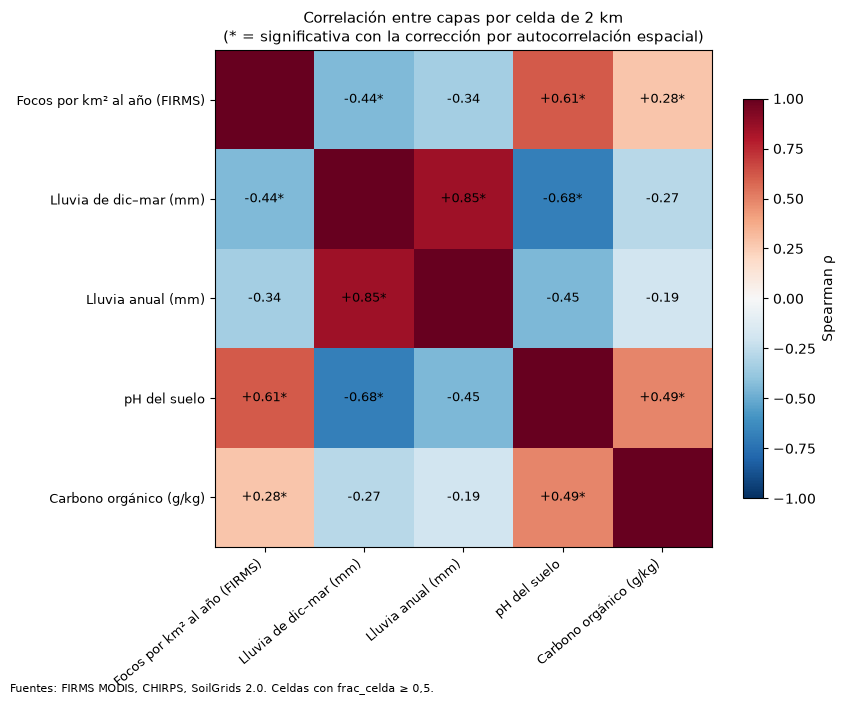

In [3]:
rng = np.random.default_rng(SEMILLA)
m = min(4000, len(d))
muestra = rng.choice(len(d), m, replace=False)
xy = d[['x_km', 'y_km']].to_numpy(float)[muestra]
# pares aleatorios (en vez de todos) para que sea rápido: 2 millones de pares
i = rng.integers(0, m, 2_000_000); j = rng.integers(0, m, 2_000_000)
ok = i != j; i, j = i[ok], j[ok]
dist = np.hypot(*(xy[i] - xy[j]).T)
clase = np.minimum((dist // 10).astype(int), 59)            # clases de 10 km hasta 600 km
p_k = np.bincount(clase, minlength=60) / len(clase)

def rho_k(v):
    z = stats.rankdata(v); z = (z - z.mean()) / z.std()
    prod = z[muestra][i] * z[muestra][j]
    suma = np.bincount(clase, weights=prod, minlength=60)
    cuenta = np.bincount(clase, minlength=60)
    return np.divide(suma, cuenta, out=np.zeros(60), where=cuenta > 0)

RHO = {v: rho_k(d[v].to_numpy()) for v in VARIABLES}
n = len(d)
filas = []
nombres = list(VARIABLES)
for a_i, a in enumerate(nombres):
    for b in nombres[a_i + 1:]:
        r = stats.spearmanr(d[a], d[b])[0]
        var_r = 1 / n + (n - 1) / n * np.sum(p_k * RHO[a] * RHO[b])
        n_ef = float(np.clip(1 / var_r, 3, n))
        t = r * np.sqrt((n_ef - 2) / (1 - r ** 2))
        p = 2 * stats.t.sf(abs(t), n_ef - 2)
        p_ingenuo = 2 * stats.t.sf(abs(r * np.sqrt((n - 2) / (1 - r ** 2))), n - 2)
        filas.append({'variable_1': a, 'variable_2': b, 'spearman': r, 'n_celdas': n,
                      'n_efectivo': n_ef, 'p_corregido': p, 'p_sin_corregir': p_ingenuo})
corr = pd.DataFrame(filas)
print(corr.round({'spearman': 3, 'n_efectivo': 0, 'p_corregido': 4, 'p_sin_corregir': 4}).to_string(index=False))

mat = pd.DataFrame(np.eye(len(nombres)), index=nombres, columns=nombres)
for _, f in corr.iterrows():
    mat.loc[f.variable_1, f.variable_2] = mat.loc[f.variable_2, f.variable_1] = f.spearman
sig = {(f.variable_1, f.variable_2): f.p_corregido < 0.05 for _, f in corr.iterrows()}
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(mat, cmap='RdBu_r', vmin=-1, vmax=1)
etiq = [VARIABLES[v] for v in nombres]
ax.set_xticks(range(len(nombres)), etiq, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(len(nombres)), etiq, fontsize=9)
for a_i, a in enumerate(nombres):
    for b_i, b in enumerate(nombres):
        if a_i != b_i:
            s = sig.get((a, b), sig.get((b, a)))
            ax.text(b_i, a_i, f'{mat.iloc[a_i, b_i]:+.2f}' + ('*' if s else ''), ha='center', va='center', fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8, label='Spearman ρ')
ax.set_title('Correlación entre capas por celda de 2 km\n(* = significativa con la corrección por autocorrelación espacial)', fontsize=11)
fig.text(0.01, 0.01, 'Fuentes: FIRMS MODIS, CHIRPS, SoilGrids 2.0' + (', MapBiomas' if len(nombres) > 5 else '') + '. Celdas con frac_celda ≥ 0,5.', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAF_INT}/61_matriz_correlacion.png', dpi=150, bbox_inches='tight')
plt.show()

## Paso 4. Comparación por clase de acidez y la hipótesis de Cumaribo

En la Altillanura casi no hay suelos alcalinos: la comparación útil es entre grados de acidez (clases del cuaderno 42). Para cada clase se resume la mediana de cada variable. Es una tabla **descriptiva**: las celdas de una misma clase están agrupadas en el espacio, así que no se le aplica una prueba que suponga independencia; la prueba formal es la del paso 3 y el LISA del paso 5.

Además se compara **Cumaribo frente al resto** de la región, que es la forma concreta de la hipótesis del profesor.

Mediana por clase de pH:
                                  focos_km2_anio  lluvia_seca_1991_2020  lluvia_anual_1991_2020  ph_medio  cos_medio_gkg  celdas
clase_ph                                                                                                                        
extremadamente acido (<4.5)                 0.00                 461.00                 3075.70      4.49          19.84      74
muy fuertemente acido (4.5-5.0)             0.00                 415.00                 2897.83      4.75          17.15   11489
fuertemente acido (5.1-5.5)                 0.09                 263.71                 2674.37      5.14          19.75   22341
moderadamente acido o mas (>5.5)            0.07                 192.16                 2472.75      5.52          35.96       9

Mediana Cumaribo vs. resto:
                         focos_km2_anio  lluvia_seca_1991_2020  lluvia_anual_1991_2020  ph_medio  cos_medio_gkg  celdas
zona                                                

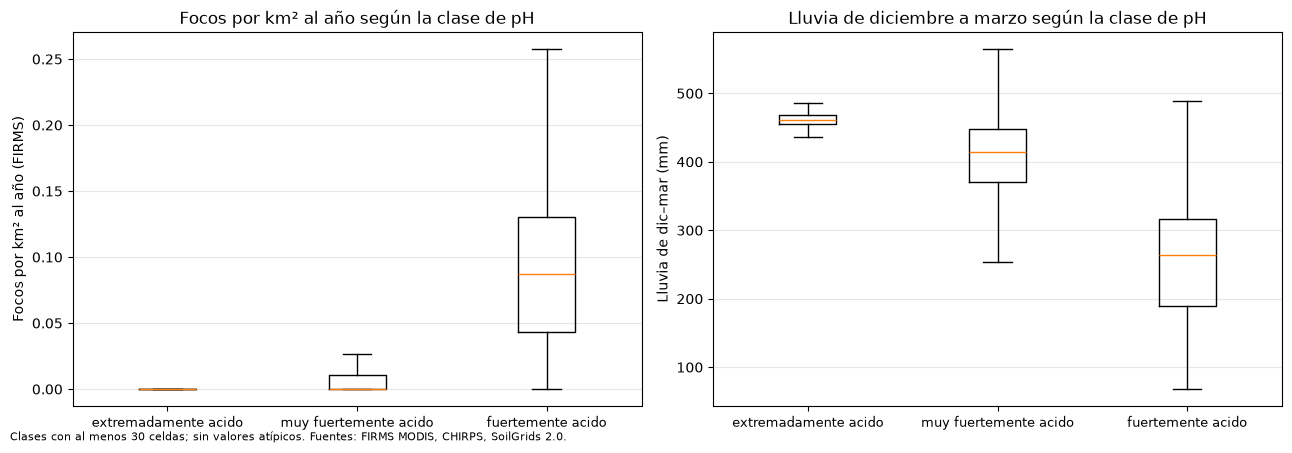

In [4]:
orden = ['extremadamente acido (<4.5)', 'muy fuertemente acido (4.5-5.0)',
         'fuertemente acido (5.1-5.5)', 'moderadamente acido o mas (>5.5)']
por_clase = (d.groupby('clase_ph')[nombres].median()
             .join(d.groupby('clase_ph').size().rename('celdas'))
             .reindex([c for c in orden if c in d['clase_ph'].unique()]))
print('Mediana por clase de pH:'); print(por_clase.round(2).to_string())

d['zona'] = np.where(d['mpio_cnmbr'].str.upper().str.contains('CUMARIBO'), 'Cumaribo', 'Resto de la Altillanura')
por_zona = d.groupby('zona')[nombres].median().join(d.groupby('zona').size().rename('celdas'))
print('\nMediana Cumaribo vs. resto:'); print(por_zona.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
clases_presentes = [c for c in orden if (d['clase_ph'] == c).sum() >= 30]
for ax, v in zip(axes, ['focos_km2_anio', 'lluvia_seca_1991_2020']):
    datos = [d.loc[d['clase_ph'] == c, v] for c in clases_presentes]
    ax.boxplot(datos, showfliers=False)
    ax.set_xticks(range(1, len(clases_presentes) + 1), [c.split(' (')[0] for c in clases_presentes], fontsize=9)
    ax.set_ylabel(VARIABLES[v]); ax.grid(alpha=0.3, axis='y')
axes[0].set_title('Focos por km² al año según la clase de pH')
axes[1].set_title('Lluvia de diciembre a marzo según la clase de pH')
fig.text(0.01, 0.01, 'Clases con al menos 30 celdas; sin valores atípicos. Fuentes: FIRMS MODIS, CHIRPS, SoilGrids 2.0.', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAF_INT}/61_por_clase_ph.png', dpi=150, bbox_inches='tight')
plt.show()

## Paso 5. Moran global y LISA bivariado

**Qué mide.** El **LISA bivariado** (Anselin, 1995) compara el valor de una variable en cada celda con el promedio de **otra** variable en sus vecinas. Para "focos vs. pH":

$$I_i^{BV} = z_{x,i} \sum_j w_{ij}\, z_{y,j}$$

con $x$ = focos por km² al año, $y$ = pH, ambos estandarizados, y $w_{ij}$ = pesos de vecindad (las 8 celdas que tocan a la celda $i$, normalizados para sumar 1). Cada celda significativa cae en un cuadrante:

| Cuadrante | Significado (focos vs. pH) |
|---|---|
| **Alto–Alto** | Muchos focos, rodeados de suelos menos ácidos |
| **Bajo–Bajo** | Pocos focos, rodeados de suelos más ácidos |
| **Alto–Bajo** | Muchos focos, rodeados de suelos más ácidos |
| **Bajo–Alto** | Pocos focos, rodeados de suelos menos ácidos |

**Significancia:** 999 permutaciones condicionales por celda (se reordenan al azar los valores de las vecinas). Se marcan las celdas con p < 0,05. Con decenas de miles de celdas habrá falsos positivos, así que el mapa se lee como **zonas** donde se concentran las celdas significativas, no celda por celda.

**Vecindad:** reina (queen), construida desde `id_celda`: dos celdas son vecinas si sus esquinas están a 2 km o menos en x y en y.

Se calcula para focos vs. pH, focos vs. lluvia de la temporada seca y, si existen, focos vs. cambio agropecuario y pH vs. cambio agropecuario.

Celdas: 33,913 | vecinas promedio: 7.9 | sin vecinas: 0


focos_km2_anio vs. ph_medio: I bivariado = +0.519 (p = 0.001) | Alto–Alto: 7,031, Bajo–Alto: 4,797, Bajo–Bajo: 9,211, Alto–Bajo: 367


focos_km2_anio vs. lluvia_seca_1991_2020: I bivariado = -0.333 (p = 0.001) | Alto–Alto: 1,924, Bajo–Alto: 8,763, Bajo–Bajo: 4,568, Alto–Bajo: 5,232


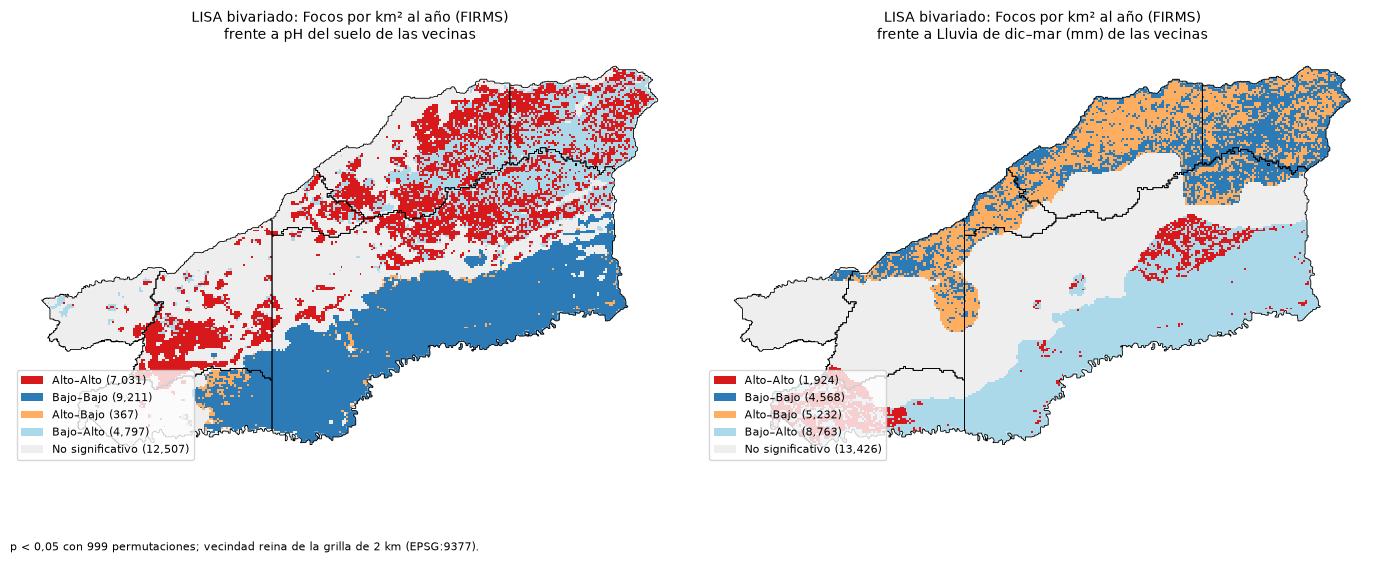


% de celdas de cada municipio por cuadrante (focos_km2_anio vs. ph_medio):
focos_km2_anio__ph_medio  Alto–Alto  Alto–Bajo  Bajo–Alto  Bajo–Bajo  No significativo
municipio                                                                             
CUMARIBO                       13.1        1.0       10.0       49.7              26.1
LA PRIMAVERA                   40.3        0.0       26.1        0.0              33.6
MAPIRIPÁN                       1.5        6.4        0.4       31.8              59.9
PUERTO CARREÑO                 41.1        0.0       51.8        0.0               7.2
PUERTO GAITÁN                  31.8        0.1        4.1        3.7              60.3
PUERTO LÓPEZ                    4.4        0.0        5.8        0.0              89.8
SANTA ROSALÍA                  30.9        0.0       10.4        0.0              58.7


In [5]:
pos = {(x, y): k for k, (x, y) in enumerate(zip(d['x_km'], d['y_km']))}
vecinos = {k: [pos[(x + dx, y + dy)] for dx in (-2, 0, 2) for dy in (-2, 0, 2)
               if (dx or dy) and (x + dx, y + dy) in pos]
           for (x, y), k in pos.items()}
aisladas = [k for k, v in vecinos.items() if not v]
w = libpysal.weights.W(vecinos, silence_warnings=True)
w.transform = 'r'
print(f'Celdas: {w.n:,} | vecinas promedio: {w.mean_neighbors:.1f} | sin vecinas: {len(aisladas)}')

PARES = [('focos_km2_anio', 'ph_medio'), ('focos_km2_anio', 'lluvia_seca_1991_2020')]
if 'cambio_agro_pp' in d.columns:
    PARES += [('focos_km2_anio', 'cambio_agro_pp'), ('ph_medio', 'cambio_agro_pp')]
if 'quema_media_anual_pct' in d.columns:
    PARES += [('quema_media_anual_pct', 'ph_medio')]

ETIQ = {1: 'Alto–Alto', 2: 'Bajo–Alto', 3: 'Bajo–Bajo', 4: 'Alto–Bajo'}
glob, lisa = [], pd.DataFrame({'id_celda': d['id_celda']})
for x, y in PARES:
    gm = esda.Moran_BV(d[x].values, d[y].values, w, permutations=999)
    lm = esda.Moran_Local_BV(d[x].values, d[y].values, w, permutations=999, seed=SEMILLA)
    cuad = np.where(lm.p_sim < 0.05, lm.q, 0)
    lisa[f'{x}__{y}'] = pd.Series(cuad).map(ETIQ).fillna('No significativo').values
    conteo = lisa[f'{x}__{y}'].value_counts()
    glob.append({'x': x, 'y': y, 'I_bivariado': gm.I, 'p_permutacion': gm.p_sim,
                 **{f'celdas_{e}': int(conteo.get(e, 0)) for e in list(ETIQ.values()) + ['No significativo']}})
    print(f'{x} vs. {y}: I bivariado = {gm.I:+.3f} (p = {gm.p_sim:.3f}) | ' +
          ', '.join(f'{e}: {conteo.get(e, 0):,}' for e in ETIQ.values()))
glob = pd.DataFrame(glob)

colores = {'Alto–Alto': '#d7191c', 'Bajo–Bajo': '#2c7bb6', 'Alto–Bajo': '#fdae61',
           'Bajo–Alto': '#abd9e9', 'No significativo': '#eeeeee'}
mpios = d.dissolve(by='mpio_cnmbr')
fig, axes = plt.subplots(1, len(PARES), figsize=(7 * len(PARES), 6), squeeze=False)
for ax, (x, y) in zip(axes[0], PARES):
    col = lisa[f'{x}__{y}']
    for e, c in colores.items():
        sub = d[col.values == e]
        if len(sub):
            sub.plot(ax=ax, color=c, linewidth=0, label=f'{e} ({len(sub):,})')
    mpios.boundary.plot(ax=ax, color='black', linewidth=0.6)
    ax.set_title(f'LISA bivariado: {VARIABLES[x]}\nfrente a {VARIABLES[y]} de las vecinas', fontsize=10)
    ax.legend(fontsize=8, loc='lower left'); ax.set_axis_off()
fig.text(0.01, 0.01, 'p < 0,05 con 999 permutaciones; vecindad reina de la grilla de 2 km (EPSG:9377).', fontsize=8)
plt.tight_layout()
plt.savefig(f'{GRAF_INT}/61_lisa_bivariado.png', dpi=150, bbox_inches='tight')
plt.show()

por_mpio = (lisa.assign(municipio=d['mpio_cnmbr'].values)
            .groupby('municipio')[f'{PARES[0][0]}__{PARES[0][1]}'].value_counts(normalize=True)
            .mul(100).unstack(fill_value=0).round(1))
print(f'\n% de celdas de cada municipio por cuadrante ({PARES[0][0]} vs. {PARES[0][1]}):')
print(por_mpio.to_string())

### Cómo leer los resultados

- **Matriz de correlación (paso 3).** El signo dice la dirección; el asterisco, si la relación resiste la corrección por autocorrelación. Compara las columnas `p_corregido` y `p_sin_corregir`: la diferencia muestra cuánto inflaría la significancia ignorar que las celdas vecinas no son independientes. El `n_efectivo` indica a cuántas observaciones independientes equivalen las ~33.000 celdas.
- **Por clase de pH y Cumaribo (paso 4).** Si las celdas muy fuertemente ácidas y Cumaribo tienen una mediana de focos menor, el dato apoya la hipótesis del profesor de forma descriptiva.
- **LISA bivariado (paso 5).** Las zonas **Bajo–Bajo** (pocos focos junto a suelos más ácidos) en Cumaribo y Mapiripán, y **Alto–Alto** en el occidente o el norte, serían la versión espacial de esa hipótesis.

**Advertencias para el informe:**
1. **Correlación no es causa.** Que haya menos focos sobre suelos más ácidos puede deberse a otra variable que cambia en la misma dirección, como la lluvia de la temporada seca: el sur es a la vez más ácido y más lluvioso. Por eso la lluvia está en la matriz: si pH y lluvia de dic–mar están muy correlacionados, el efecto del pH no se puede separar del clima con correlaciones simples. Eso lo hace el modelo integrador (cuaderno 63).
2. **SoilGrids usa la cobertura del suelo como covariable**, así que la relación entre pH y uso agropecuario puede ser en parte circular.
3. **CHIRPS tiene un artefacto rectangular** en el nororiente (cuaderno 12); conviene repetir las correlaciones de lluvia sin esas celdas.
4. Los periodos no coinciden del todo: focos 2003–2025, lluvia normal 1991–2020, quema 2015–2025, suelo sin fecha.

### Resultados y conclusiones

**1. La autocorrelación espacial cambia por completo la significancia.** Con 33.913 celdas, todos los p-valores sin corregir dan 0,0. Pero las celdas vecinas se parecen tanto que, al corregir con Clifford, Richardson y Hémon (1989), el **tamaño efectivo de muestra queda entre 12 y 57 "celdas independientes"**. Con esa corrección, varias relaciones dejan de ser significativas. Sin ella habríamos reportado todo como significativo.

**2. Fuego y lluvia: lo que importa es la temporada seca.**

| Relación con focos/km²/año | Spearman | n efectivo | p corregido |
|---|---|---|---|
| Lluvia de dic–mar (1991–2020) | **−0,44** | 23 | **0,032** |
| Lluvia anual | −0,34 | 25 | 0,095 (no signif.) |
| pH del suelo | **+0,61** | 28 | **0,0006** |
| Carbono orgánico (COS) | +0,28 | 57 | 0,035 |

Donde llueve menos de diciembre a marzo hay más focos. La lluvia anual total no alcanza significancia. Es el mismo mecanismo del cuaderno 21 (menos lluvia, más fuego), ahora visto en el espacio: lo que cuenta es cuán seca es la temporada seca, no cuánto llueve en el año.

**3. Fuego y acidez: la correlación más fuerte, pero con una explicación compartida.** Las celdas menos ácidas (pH más alto) tienen más fuego (ρ = +0,61, la relación más fuerte de la tabla). Sin embargo, el pH también está muy correlacionado con la lluvia de la temporada seca (**ρ = −0,68**, p = 0,009): el norte, más seco, es menos ácido, y el sur, más lluvioso, más ácido. Por eso **no se puede decir que la acidez reduzca el fuego**. Lo más probable es que el gradiente de lluvia sur–norte esté detrás de ambas variables (factor de confusión). Además, el pH de SoilGrids se predice en parte con covariables de clima y vegetación, lo que puede reforzar esa coincidencia.

**4. Por clase de acidez.** La celda mediana *muy fuertemente ácida* (pH 4,5–5,0; 11.489 celdas) tiene **0 focos/km²/año**: más de la mitad de esas celdas no tuvo ningún foco en 2003–2025. La celda mediana *fuertemente ácida* (pH 5,1–5,5; 22.341 celdas) tiene **0,087 focos/km²/año**. Las clases extremas (74 celdas con pH < 4,5 y 9 con pH > 5,5) son demasiado pocas para sacar conclusiones.

**5. Cumaribo frente al resto.**

| Mediana por celda | Cumaribo | Resto de la Altillanura |
|---|---|---|
| Focos/km²/año | **0,011** | **0,076** (~7 veces más) |
| Lluvia dic–mar (mm) | 379 | 251 |
| pH | 4,87 | 5,13 |
| Celdas | 16.295 | 17.618 |

Cumaribo se quema mucho menos, es más ácido y tiene una temporada seca un 51 % más lluviosa. Coincide con lo encontrado por Jonatan: en Cumaribo la pradera quemada se convierte menos a uso agropecuario. Pero estas diferencias muestran que Cumaribo **difiere en lluvia y en suelo al mismo tiempo**, y estos datos no permiten separar cuál de los dos explica el menor fuego.

*Nota:* aquí se usa la **mediana** por celda (0,011). La cifra del cuaderno 22 (4,3 focos por 100 km² al año) es el promedio del municipio, que suben unas pocas celdas muy quemadas.

**6. Dónde ocurre la relación (LISA bivariado, 999 permutaciones, p < 0,05).**

| Par | I de Moran bivariado | Alto–Alto | Bajo–Bajo | Bajo–Alto | Alto–Bajo | No signif. |
|---|---|---|---|---|---|---|
| Focos ↔ pH vecino | **+0,52** (p = 0,001) | 20,7 % | 27,2 % | 14,1 % | 1,1 % | 36,9 % |
| Focos ↔ lluvia seca vecina | **−0,33** (p = 0,001) | 5,7 % | 13,5 % | 25,8 % | 15,4 % | 39,6 % |

En el primer par, casi la mitad del territorio son agrupaciones "concordantes": celdas con mucho fuego rodeadas de suelos menos ácidos (Alto–Alto) o con poco fuego rodeadas de suelos más ácidos (Bajo–Bajo). En el segundo, dominan los cuadrantes "opuestos", que son los que indican una relación negativa: poco fuego rodeado de temporadas secas lluviosas (Bajo–Alto, 25,8 %) y mucho fuego rodeado de temporadas secas secas (Alto–Bajo, 15,4 %). En ambos casos, más de un tercio de las celdas no muestra una asociación local significativa.

**Conclusión general.** A escala de celda de 2 km, el fuego se concentra donde la temporada seca es más seca y los suelos son menos ácidos, es decir, en el centro-norte de la Altillanura. Cumaribo es la gran zona de bajo fuego. Son **asociaciones espaciales, no causas**: lluvia y acidez varían juntas de sur a norte. Para separarlas se necesita un modelo con las dos variables a la vez y la expansión agropecuaria como respuesta (cuadernos 62–63).

**Limitaciones y pendientes:**
- Faltan las capas de quema por celda (Jonatan) y de expansión agropecuaria por celda (Daniel). Cuando estén en `main` se vuelve a ejecutar el cuaderno y se agregan automáticamente.
- El rectángulo artificial de CHIRPS en el nororiente puede influir en las relaciones con la lluvia. Conviene repetir excluyendo esas celdas.
- Los periodos no coinciden: la lluvia es la normal 1991–2020, el fuego cubre 2003–2025 y el suelo es una foto sin fecha.
- Con 12 a 57 observaciones efectivas, los p-valores cercanos a 0,05 (COS 0,035; lluvia seca 0,032) deben leerse con cautela.

## Paso 6. Guardar resultados

In [6]:
corr.round(5).to_csv(f'{RES_INT}/61_correlaciones_spearman.csv', index=False)
por_clase.round(4).to_csv(f'{RES_INT}/61_mediana_por_clase_ph.csv')
por_zona.round(4).to_csv(f'{RES_INT}/61_mediana_cumaribo_vs_resto.csv')
glob.round(5).to_csv(f'{RES_INT}/61_moran_bivariado_global.csv', index=False)
lisa.to_csv(f'{RES_INT}/61_lisa_bivariado_celdas.csv', index=False)
for f in sorted(os.listdir(RES_INT)):
    print(f'{f:40s} {os.path.getsize(os.path.join(RES_INT, f)) / 1e6:6.2f} MB')

if EN_COLAB:   # descarga resultados y gráficas en un ZIP
    import shutil
    from google.colab import files
    shutil.make_archive('/content/resultados_61', 'zip', os.path.join(RAIZ, 'modulos', 'integracion'))
    files.download('/content/resultados_61.zip')

61_correlaciones_spearman.csv              0.00 MB
61_lisa_bivariado_celdas.csv               1.38 MB
61_mediana_cumaribo_vs_resto.csv           0.00 MB
61_mediana_por_clase_ph.csv                0.00 MB
61_moran_bivariado_global.csv              0.00 MB
